# Dat 200 CA5 Group 4
Lasse Lindholm and Brage Bromset Bestvold

## Imports

In [6]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


# Load data

In [7]:
train = pd.read_csv("trainCA5.csv")
test = pd.read_csv("testCA5.csv")
train.head()

,id,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,smoking_status,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
0,193355,55.0,NaN,9.0,20.0,0.900000,3.7,1.1,129.0,47.7,1.0,Never,3.0,1.8,8.0,8.0,27
1,509850,23.0,6.8,8.0,66.0,-3.634081,NaN,1.8,108.0,29.9,7.0,Never,63.0,0.9,5.0,5.0,28
2,413954,70.0,9.4,9.0,13.0,2.100000,9.5,5.0,137.0,NaN,2.0,Never,1.0,2.4,8.0,5.0,25
3,94859,40.0,7.5,10.0,200.0,1.600000,5.0,0.5,124.0,NaN,0.0,Never,7.0,0.9,NaN,8.0,29
4,18214,18.0,6.9,6.0,81.0,NaN,3.6,1.2,118.0,43.2,2.0,Never,0.0,0.5,5.0,10.0,26


## Data exploration


### Correlation heatmap

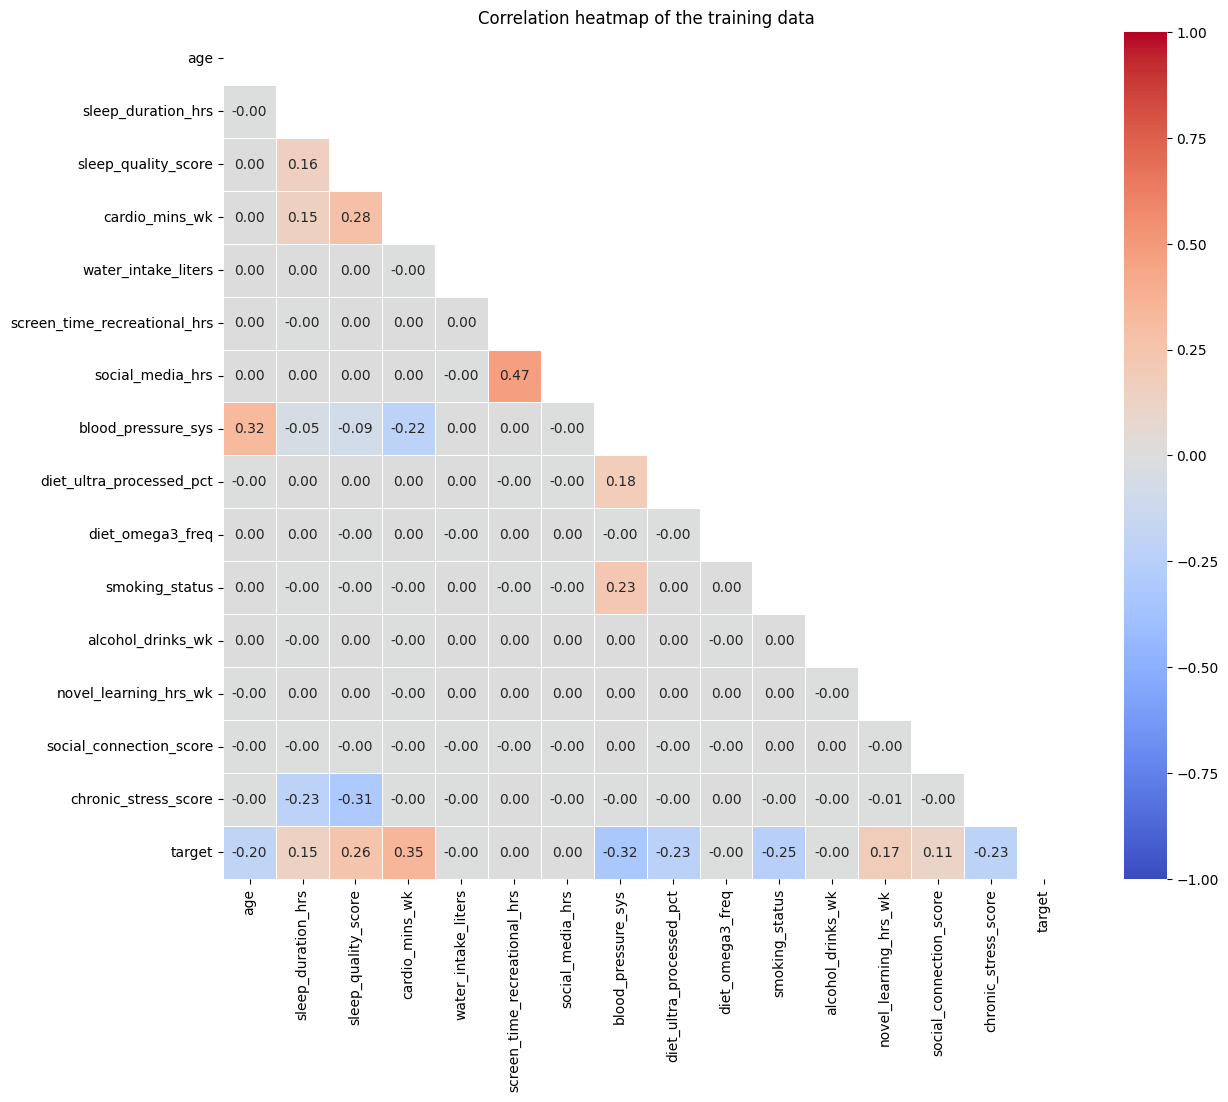

In [ ]:
# Modified correlation heatmap taken from the 04_correlationmap.ipynb example from canvas
# https://nmbu.instructure.com/courses/14056/files/folder/Lecture_12_Preprocessing?preview=2814845
def plot_correlation_heatmap(data, title, method="pearson"):
    """
    Plot a correlation heatmap (lower triangle only) for the numeric columns of a dataset.
    NaNs are handled pairwise by pandas, so missing values do not break it.
    """
    corr = data.corr(numeric_only=True, method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool))  # hide the mirrored upper triangle
    plt.figure(figsize=(14, 11))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True, linewidths=0.5)
    plt.title(title)
    plt.show()

# Id is dropped, smoking status has text so is removed for this heatmap
# Could maybe try the state trick from last CA to have 3 seperate columns for each
heatmap_data = train.drop(columns="id").copy()
heatmap_data["smoking_status"] = heatmap_data["smoking_status"].map({"Never": 0, "Former": 1, "Current": 2})

plot_correlation_heatmap(heatmap_data, "Correlation heatmap of the training data")

None of the values seem to have very strong corelations, the plan for now is to keep all

### Box plots


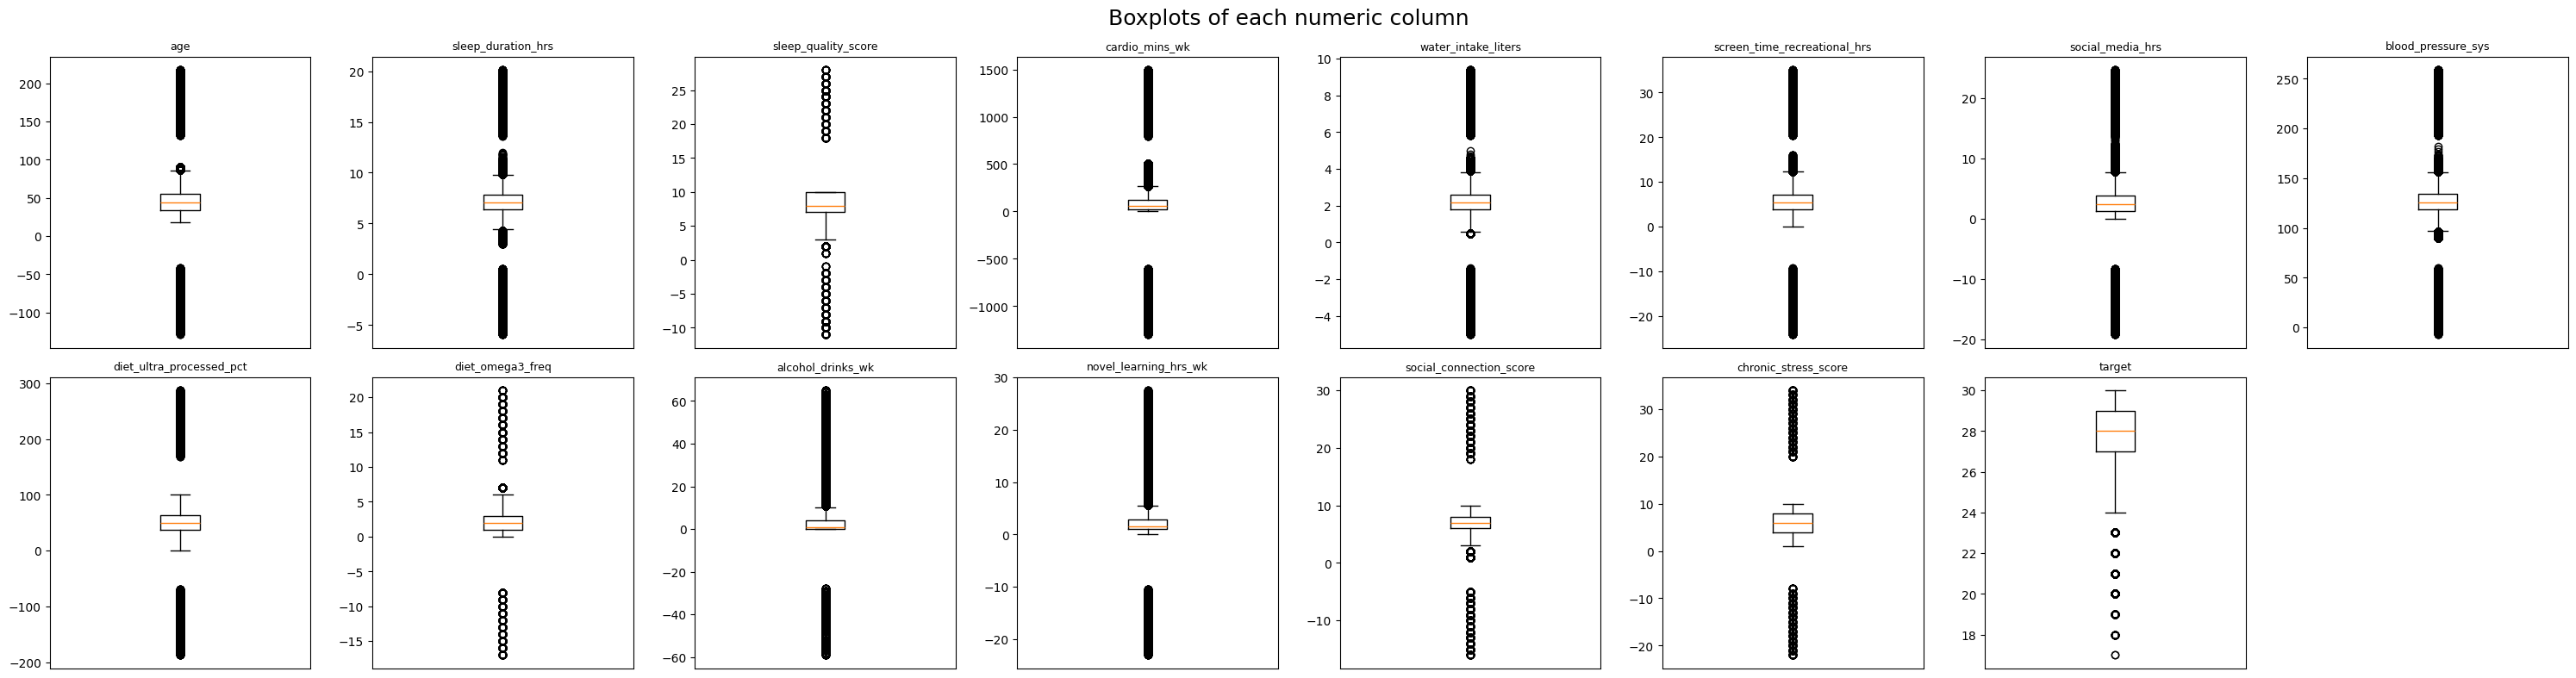

In [15]:
# Only numeric columns can be box plotted (smoking_status is text, id carries no information)
num_cols = train.drop(columns="id").select_dtypes(include="number").columns

n_cols = int(np.ceil(len(num_cols) / 2))
fig, axes = plt.subplots(2, n_cols, figsize=(30, 8))
fig.suptitle("Boxplots of each numeric column", fontsize=18)

for ax, col in zip(axes.flatten(), num_cols):
    ax.boxplot(train[col].dropna())  # NaNs must be dropped
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])

# hide the unused axes if there is an odd number of columns
for ax in axes.flatten()[len(num_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

The box plots reveal that every single column appear to have a little bit of random nonsense numbers thrown in. A very easy example is the age column whics's box plot shows a lot of dots around the 200 year mark which is just ridiculous, as well as negative 100 years old.

proposed solution is to clamp answers within sensible ranges, like ages 18-90 or even 100.

## Data cleaning

## preprocessing

## Model Evaluation